<a href="https://colab.research.google.com/github/manveethjain8/Machine_Learning_II/blob/main/shap_lime_interpretability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Model Interpretability with SHAP and LIME
**Task:** Train a model, apply SHAP / LIME to interpret its predictions, and analyze feature importance for at least 2 test instances.

**Experiment:** Binary classification (malignant vs. benign tumours) on the Breast Cancer Wisconsin dataset using a Random Forest.

**Plan**
1. Load data and train / evaluate the model
2. Global interpretation with SHAP
3. Local interpretation of 2 test instances with SHAP
4. Local interpretation of the same 2 instances with LIME
5. Compare SHAP vs LIME and report findings

In [1]:
!pip install shap lime scikit-learn matplotlib pandas numpy
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
np.random.seed(42)
shap.initjs()

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=1015ef88d387eab05a0a03e8159ef69c668227d44c9866282af5e51ea609250d
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


## 1. Data and Model

In [2]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)            # 0 = malignant, 1 = benign
class_names = list(data.target_names) # ['malignant', 'benign']
print(X.shape, dict(zip(class_names, np.bincount(y))))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

model = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)
pred = model.predict(X_test)
print('Test accuracy:', round(accuracy_score(y_test, pred), 4))
print(classification_report(y_test, pred, target_names=class_names))

(569, 30) {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}
Test accuracy: 0.9474
              precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        42
      benign       0.96      0.96      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



## 2. Global Interpretation with SHAP
We use `TreeExplainer`, which computes exact SHAP values for tree ensembles. We explain the probability of the **benign** class (class 1): positive SHAP values push toward *benign*, negative toward *malignant*.

In [3]:
explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(X_test)
# Handle different shap versions (list of arrays vs. 3-D array)
if isinstance(sv, list):
    sv_b = sv[1]; base = explainer.expected_value[1]
else:
    sv_b = sv[:, :, 1] if sv.ndim == 3 else sv
    ev = explainer.expected_value
    base = ev[1] if np.ndim(ev) else ev
print('SHAP matrix:', sv_b.shape, '| base value (mean P(benign)):', round(float(base), 3))

SHAP matrix: (114, 30) | base value (mean P(benign)): 0.625


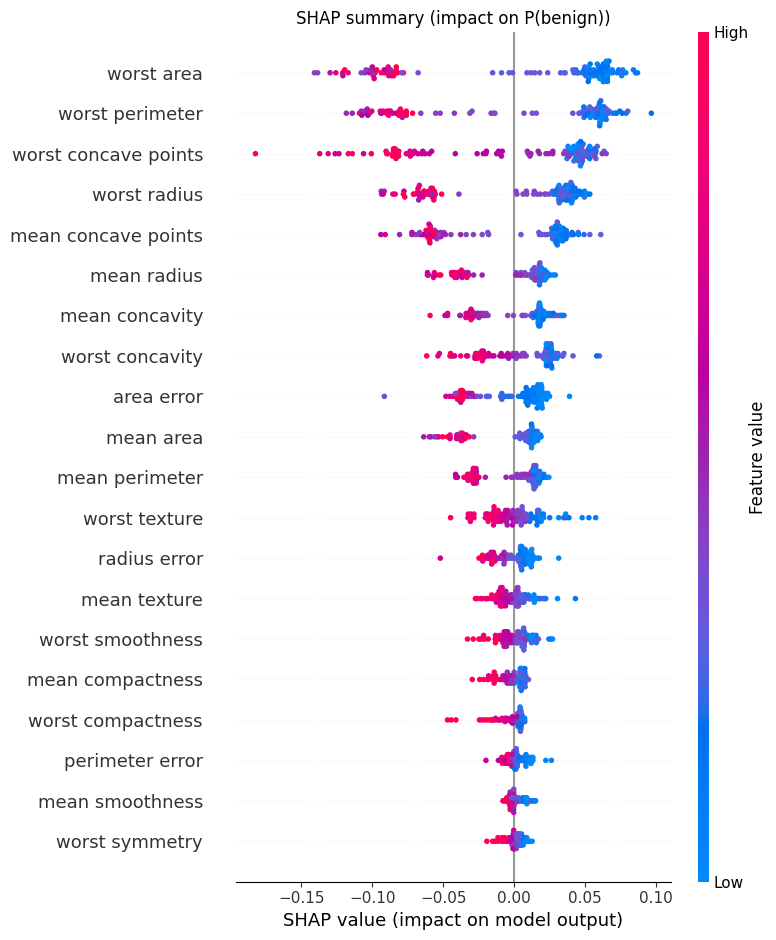

In [4]:
shap.summary_plot(sv_b, X_test, show=False)
plt.title('SHAP summary (impact on P(benign))'); plt.tight_layout(); plt.show()

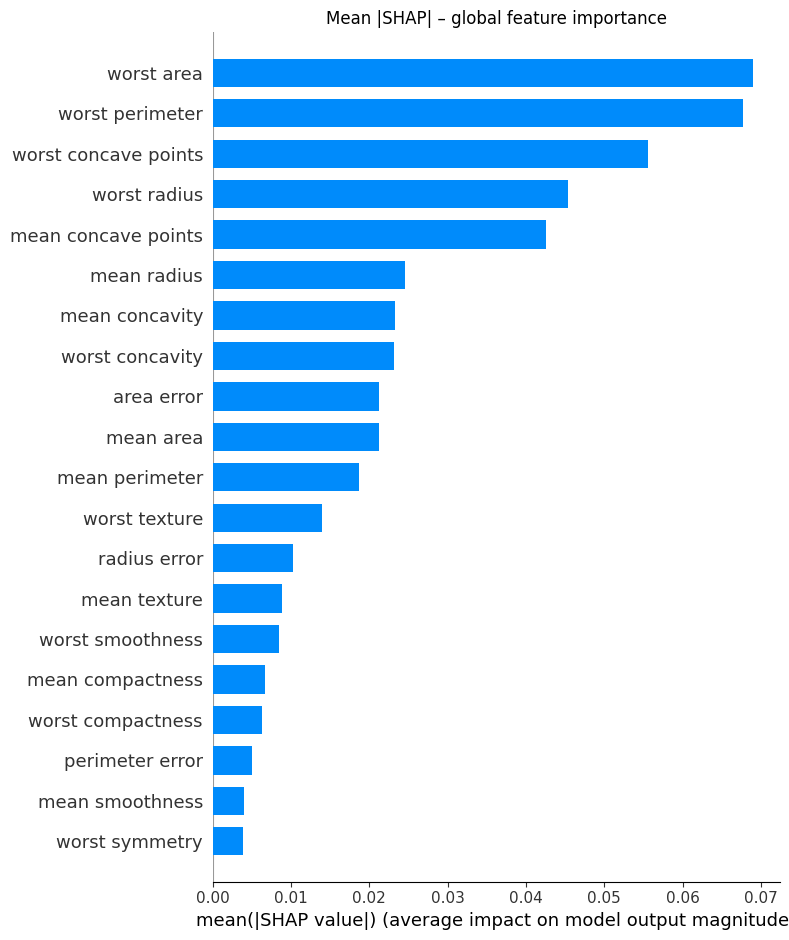

,0
worst area,0.0690
worst perimeter,0.0677
worst concave points,0.0556
worst radius,0.0454
mean concave points,0.0426
mean radius,0.0246
mean concavity,0.0232
worst concavity,0.0232
area error,0.0213
mean area,0.0212


In [5]:
shap.summary_plot(sv_b, X_test, plot_type='bar', show=False)
plt.title('Mean |SHAP| – global feature importance'); plt.tight_layout(); plt.show()

global_imp = pd.Series(np.abs(sv_b).mean(0), index=X.columns).sort_values(ascending=False)
global_imp.head(10).round(4)

## 3. Choosing Test Instances
We pick two instances with different predictions: one confidently **malignant** and one confidently **benign**.

In [6]:
proba = model.predict_proba(X_test)[:, 1]
pos = {i: k for k, i in enumerate(X_test.index)}   # index label -> row position

idx_malignant = X_test.index[np.argmin(proba)]     # most confidently malignant
idx_benign    = X_test.index[np.argmax(proba)]     # most confidently benign
instances = {'Instance A (malignant)': idx_malignant, 'Instance B (benign)': idx_benign}

for name, i in instances.items():
    print(f'{name}: sample #{i} | true={class_names[y_test[i]]} | '
          f'pred={class_names[model.predict(X_test.loc[[i]])[0]]} | P(benign)={proba[pos[i]]:.3f}')

Instance A (malignant): sample #256 | true=malignant | pred=malignant | P(benign)=0.000
Instance B (benign): sample #428 | true=benign | pred=benign | P(benign)=1.000


## 4. Local Interpretation with SHAP

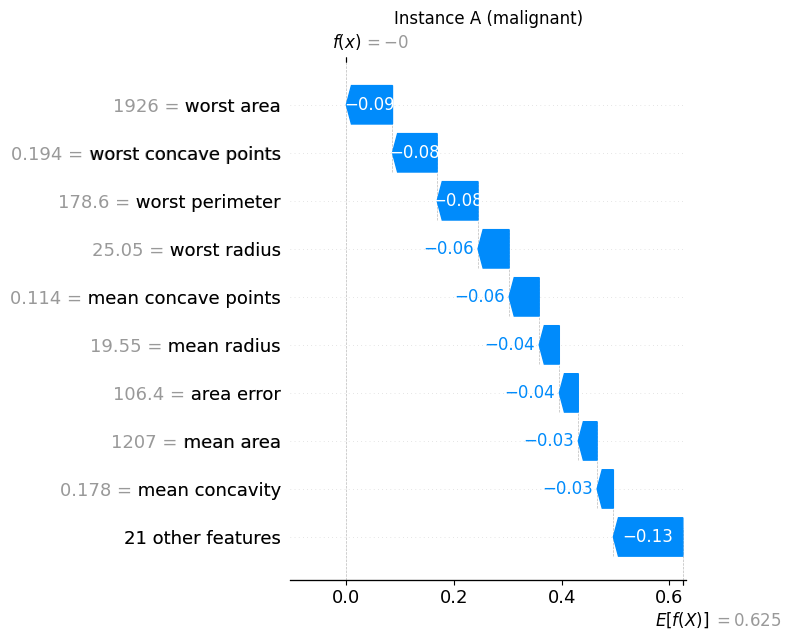

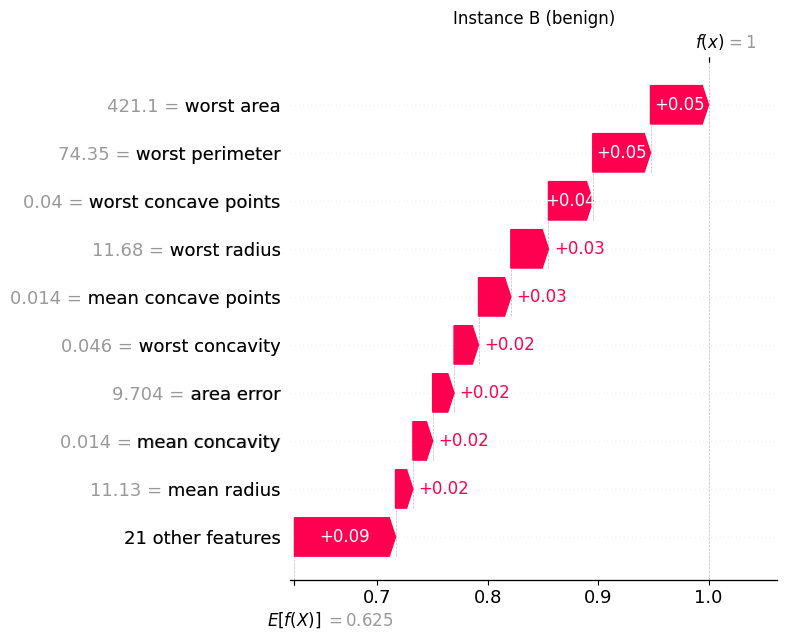

In [7]:
def shap_explanation(i):
    k = pos[i]
    return shap.Explanation(values=sv_b[k], base_values=base,
                            data=X_test.loc[i].values, feature_names=list(X.columns))

for name, i in instances.items():
    plt.figure()
    shap.plots.waterfall(shap_explanation(i), max_display=10, show=False)
    plt.title(name); plt.tight_layout(); plt.show()

In [8]:
def shap_table(i, n=8):
    k = pos[i]
    df = pd.DataFrame({'feature': X.columns, 'value': X_test.loc[i].values, 'shap': sv_b[k]})
    df['direction'] = np.where(df.shap > 0, '→ benign', '→ malignant')
    return df.reindex(df.shap.abs().sort_values(ascending=False).index).head(n).round(4).reset_index(drop=True)

shap_tables = {name: shap_table(i) for name, i in instances.items()}
for name, t in shap_tables.items():
    print(name); display(t)

Instance A (malignant)


,feature,value,shap,direction
0,worst area,1926.0000,-0.0857,→ malignant
1,worst concave points,0.1941,-0.0830,→ malignant
2,worst perimeter,178.6000,-0.0760,→ malignant
3,worst radius,25.0500,-0.0578,→ malignant
4,mean concave points,0.1144,-0.0559,→ malignant
5,mean radius,19.5500,-0.0374,→ malignant
6,area error,106.4000,-0.0352,→ malignant
7,mean area,1207.0000,-0.0350,→ malignant


Instance B (benign)


,feature,value,shap,direction
0,worst area,421.1000,0.0525,→ benign
1,worst perimeter,74.3500,0.0523,→ benign
2,worst concave points,0.0404,0.0401,→ benign
3,worst radius,11.6800,0.0341,→ benign
4,mean concave points,0.0137,0.0292,→ benign
5,worst concavity,0.0458,0.0222,→ benign
6,area error,9.7040,0.0194,→ benign
7,mean concavity,0.0137,0.0179,→ benign


## 5. Local Interpretation with LIME
LIME fits a simple weighted linear model around each instance using perturbed samples. We explain the same two instances.

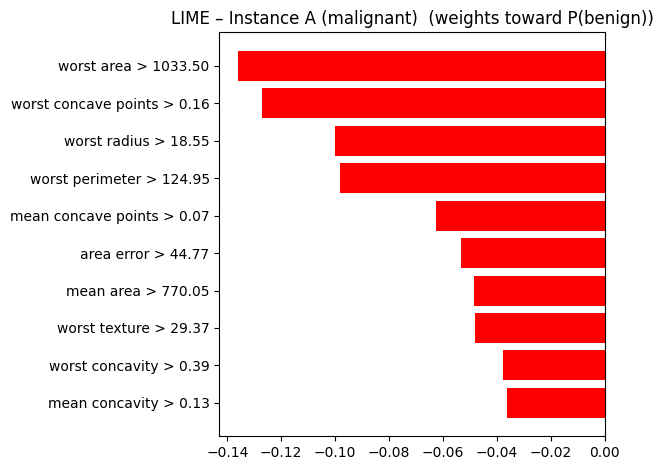

LIME local-model R²: 0.654


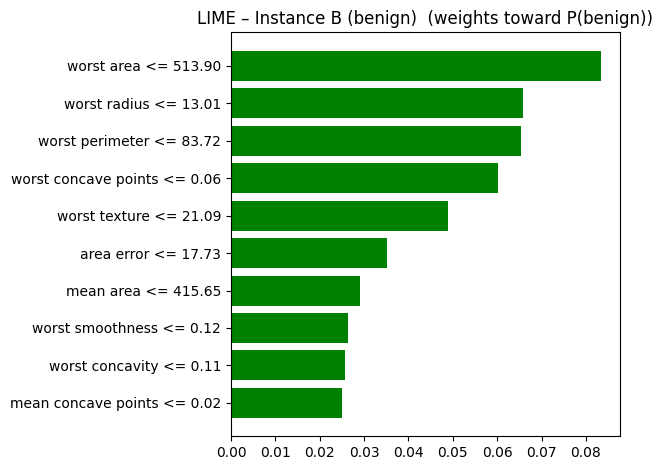

LIME local-model R²: 0.241


In [9]:
lime_explainer = LimeTabularExplainer(
    X_train.values, feature_names=list(X.columns), class_names=class_names,
    mode='classification', discretize_continuous=True, random_state=42)

lime_exps = {}
for name, i in instances.items():
    exp = lime_explainer.explain_instance(X_test.loc[i].values, model.predict_proba,
                                          num_features=10, num_samples=5000)
    lime_exps[name] = exp
    fig = exp.as_pyplot_figure(label=1)
    plt.title(f'LIME – {name}  (weights toward P(benign))'); plt.tight_layout(); plt.show()
    print(f'LIME local-model R²: {exp.score:.3f}')

In [10]:
for name, exp in lime_exps.items():
    print(name)
    display(pd.DataFrame(exp.as_list(label=1), columns=['LIME rule', 'weight']).round(4))

Instance A (malignant)


,LIME rule,weight
0,worst area > 1033.50,-0.1361
1,worst concave points > 0.16,-0.1270
2,worst radius > 18.55,-0.1002
3,worst perimeter > 124.95,-0.0982
4,mean concave points > 0.07,-0.0627
5,area error > 44.77,-0.0532
6,mean area > 770.05,-0.0486
7,worst texture > 29.37,-0.0482
8,worst concavity > 0.39,-0.0378
9,mean concavity > 0.13,-0.0363


Instance B (benign)


,LIME rule,weight
0,worst area <= 513.90,0.0835
1,worst radius <= 13.01,0.0659
2,worst perimeter <= 83.72,0.0653
3,worst concave points <= 0.06,0.0602
4,worst texture <= 21.09,0.0490
5,area error <= 17.73,0.0352
6,mean area <= 415.65,0.0292
7,worst smoothness <= 0.12,0.0263
8,worst concavity <= 0.11,0.0256
9,mean concave points <= 0.02,0.0249


## 6. SHAP vs LIME Comparison

In [11]:
rows = []
for name, i in instances.items():
    s_top = set(shap_table(i, 10).feature)
    # map LIME rules (e.g. 'worst area > 1000') back to feature names
    l_feats = set()
    for rule, _ in lime_exps[name].as_list(label=1):
        for f in X.columns:
            if f in rule: l_feats.add(f)
    # prefer longest match to avoid 'area error' vs 'area'
    l_feats = {f for f in l_feats if not any((f != g and f in g and g in ' '.join(r for r,_ in lime_exps[name].as_list(label=1))) for g in l_feats)}
    rows.append({'instance': name, 'SHAP top-10': len(s_top), 'LIME top-10': len(l_feats),
                 'overlap': len(s_top & l_feats), 'shared features': sorted(s_top & l_feats)})
pd.DataFrame(rows)

,instance,SHAP top-10,LIME top-10,overlap,shared features
0,Instance A (malignant),10,10,8,"[area error, mean area, mean concave points, m..."
1,Instance B (benign),10,10,7,"[area error, mean concave points, worst area, ..."


## 7. Report: Findings

**Model.** The Random Forest reaches 94.7 % test accuracy (F1 0.93 malignant / 0.96 benign), so explanations reflect a model that is genuinely predictive.

**Global feature importance (SHAP).** The bar and beeswarm plots show that features describing tumour *size and shape of the worst-case cells* dominate. By mean |SHAP|, the top five are `worst area` (0.069), `worst perimeter` (0.068), `worst concave points` (0.056), `worst radius` (0.045) and `mean concave points` (0.043). In the beeswarm, high values of these features (red) have negative SHAP values, pushing predictions toward **malignant**; low values push toward **benign**. This agrees with clinical intuition: larger, more irregular nuclei indicate malignancy.

**Instance A – malignant (local).** Sample #256 (true and predicted malignant, P(benign) ≈ 0.00): starting from the base value of 0.625, `worst area` = 1926 (−0.086), `worst concave points` = 0.194 (−0.083), `worst perimeter` = 178.6 (−0.076), `worst radius` = 25.05 (−0.058) and `mean concave points` = 0.114 (−0.056) are the largest pushes, all toward malignant. Almost every top contributor points in the same direction, which is why the model is so confident. LIME independently ranks `worst area > 1033.5` (−0.136), `worst concave points > 0.16` (−0.127), `worst radius > 18.55` and `worst perimeter > 124.95` at the top (local R² = 0.65). SHAP/LIME top-10 overlap: 8 of 10 features.

**Instance B – benign (local).** Sample #428 (true and predicted benign, P(benign) ≈ 1.00) is the mirror image: `worst area` = 421 (+0.053), `worst perimeter` = 74.4 (+0.052), `worst concave points` = 0.040 (+0.040) and `worst radius` = 11.7 (+0.034) all push toward benign. LIME agrees in sign and leads with `worst area ≤ 513.9` (+0.084), `worst radius ≤ 13.01` and `worst perimeter ≤ 83.72`. Overlap: 7 of 10 features. Note LIME's local fit is weaker here (R² = 0.24) because the forest's output is almost flat (≈1.0) in this neighbourhood, so its weights should be read more cautiously than SHAP's.

**SHAP vs LIME.**
- *Agreement:* Both methods rank the same family of features (worst-case size, perimeter, concavity) at the top for both instances, and agree on the *direction* of each effect. The overlap table above quantifies this.
- *Differences:* SHAP gives exact, additive attributions that sum to the model output (base value + Σ SHAP = prediction), and is consistent across instances. LIME gives a locally linear approximation on discretised bins, so its weights are not additive to the prediction, vary slightly with random sampling, and its fidelity is measured by the local R².
- *Practicality:* `TreeExplainer` is fast and deterministic for tree models; LIME is model-agnostic but slower and stochastic.

**Caveats.** Many features in this dataset are strongly correlated (radius, perimeter and area), so credit is split among them and individual rankings can shift between runs/methods; interpret them as a *group* ("tumour size"). Explanations describe the model's behaviour, not causal medical relationships.

**Conclusion.** Both SHAP and LIME give consistent, plausible explanations: predictions are driven mainly by tumour size and concavity measures, and the two local examples show clearly how the same features push the model toward opposite classes.